**Problem:** Unexpected industrial machine failures can cause unplanned downtime, production losses, and maintenance costs.

**Dataset Understanding:**
The AI4I dataset contains machine/sensor information such as:

1. Air temperature [K]
2. Process temperature [K]
3. Rotational speed [rpm]
4. Torque [Nm]
5. Tool wear [min]
6. Machine failure
7. TWF
8. HDF
9. PWF
10. OSF
11. RNF





**Objective:**
Develop an end-to-end predictive maintenance system that predicts
whether an industrial machine is likely to fail and, when failure
occurs, identifies the most probable failure mode.

In [44]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [46]:
df = pd.read_csv("/content/drive/MyDrive/Machine_Failure_Project/data/predictive_maintenance.csv")
df.head(5)

,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure,TWF,HDF,PWF,OSF,RNF
0,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [47]:
df.shape

(10000, 12)

In [48]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Type                 10000 non-null  object 
 1   Air temperature      10000 non-null  float64
 2   Process temperature  10000 non-null  float64
 3   Rotational speed     10000 non-null  int64  
 4   Torque               10000 non-null  float64
 5   Tool wear            10000 non-null  int64  
 6   Machine failure      10000 non-null  int64  
 7   TWF                  10000 non-null  int64  
 8   HDF                  10000 non-null  int64  
 9   PWF                  10000 non-null  int64  
 10  OSF                  10000 non-null  int64  
 11  RNF                  10000 non-null  int64  
dtypes: float64(3), int64(8), object(1)
memory usage: 937.6+ KB


In [49]:
df.isnull().sum()

,0
Type,0
Air temperature,0
Process temperature,0
Rotational speed,0
Torque,0
Tool wear,0
Machine failure,0
TWF,0
HDF,0
PWF,0


In [50]:
df['Machine failure'].value_counts()

,count
Machine failure,
0,9661
1,339


EDA:

In [51]:
df.columns
#print(df.shape)

Index(['Type', 'Air temperature', 'Process temperature', 'Rotational speed',
       'Torque', 'Tool wear', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='object')

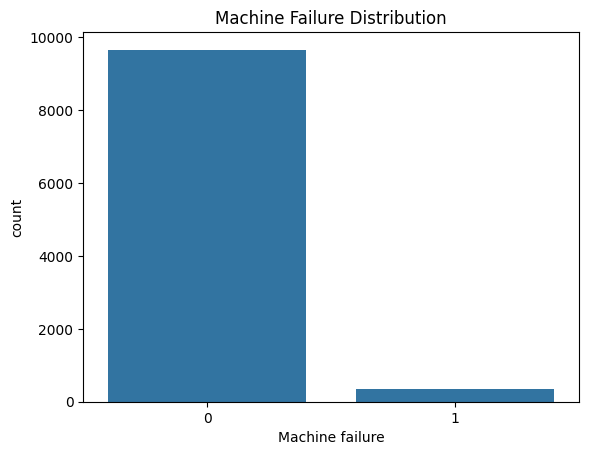

In [52]:
sns.countplot(data = df, x= 'Machine failure')
plt.title('Machine Failure Distribution')
plt.show()

From the above graph most machines do not fail, while only a small fraction experience failure. Therefore, accuracy alone can be misleading

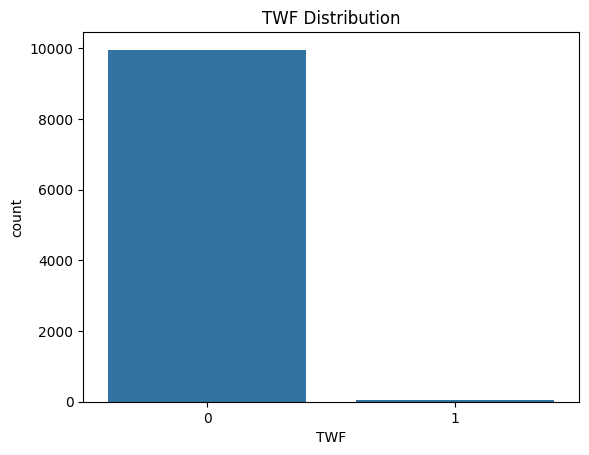

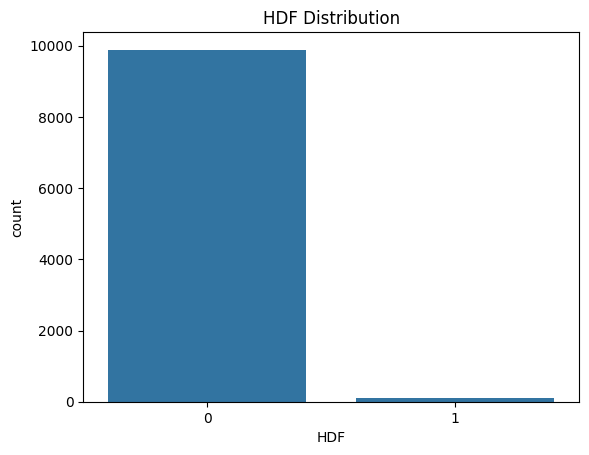

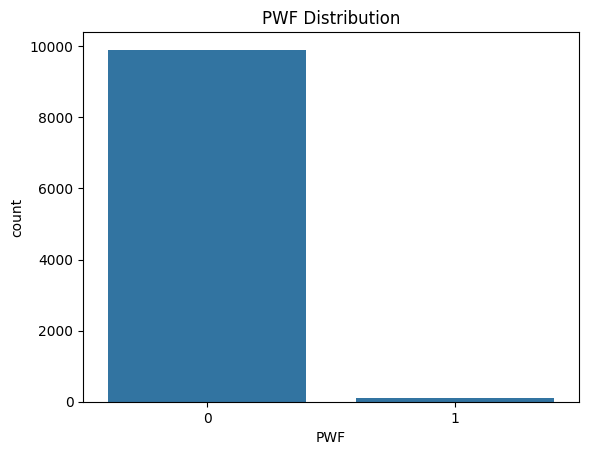

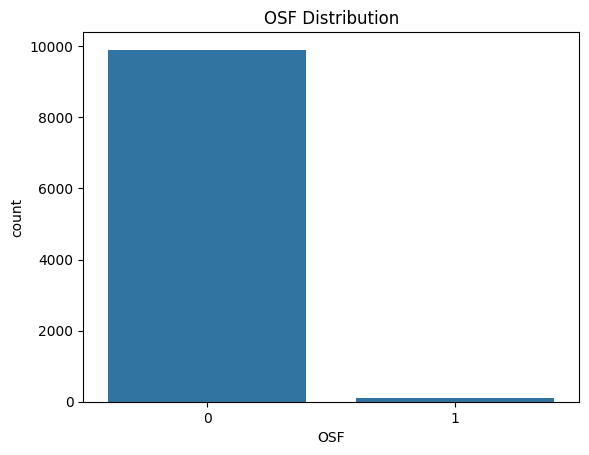

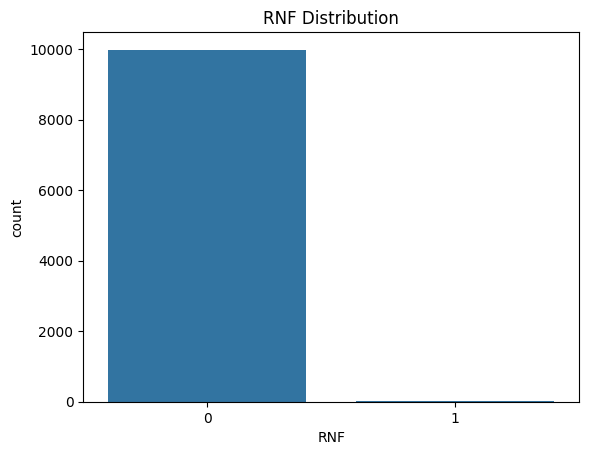

In [53]:
failure_types = ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']
for fail in failure_types:
  sns.countplot(data = df, x= fail)
  plt.title(f'{fail} Distribution')
  plt.show()



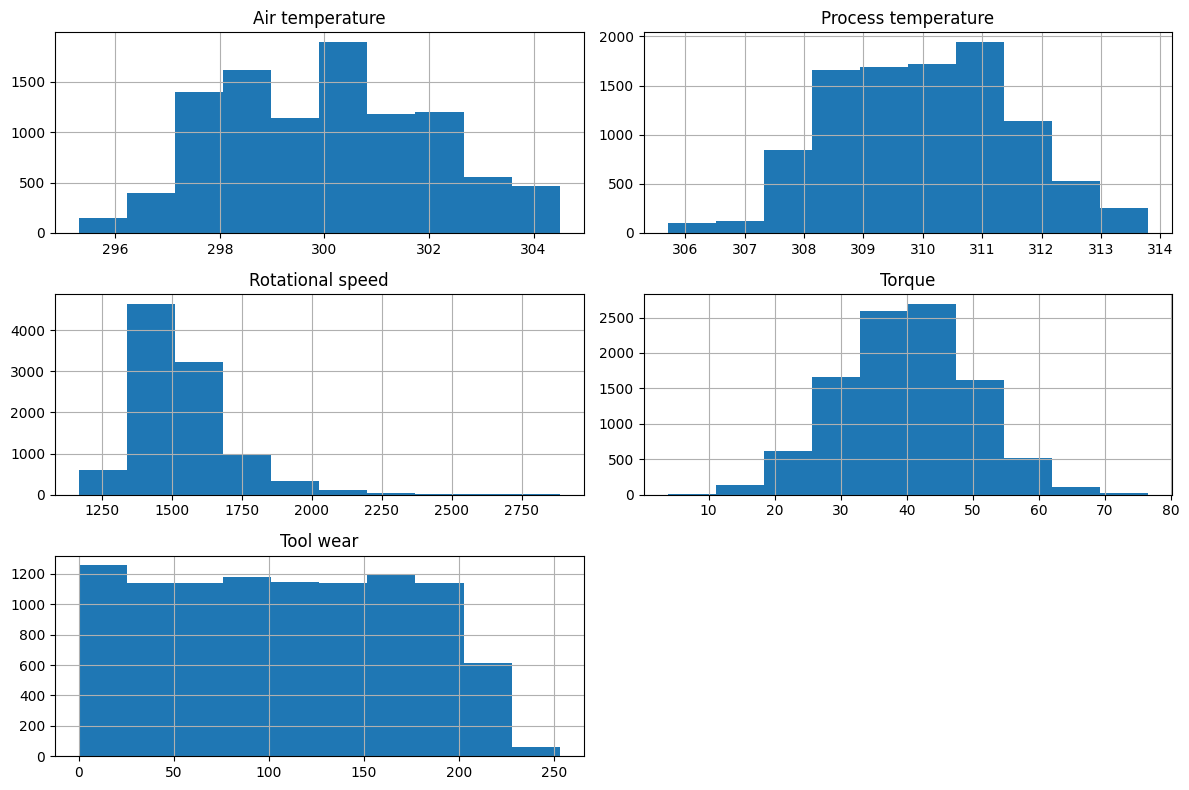

In [54]:
col =['Air temperature', 'Process temperature', 'Rotational speed','Torque', 'Tool wear']

df[['Air temperature',
    'Process temperature',
    'Rotational speed',
    'Torque',
    'Tool wear']].hist(figsize=(12,8))
plt.tight_layout()

In [55]:
import plotly.express as px


col = ['Air temperature', 'Process temperature', 'Rotational speed', 'Torque', 'Tool wear']

for c in col:
    fig = px.histogram(
        df,
        x=c,
        marginal='box',
        title=f'Distribution of {c}',
        template='plotly_white',
        opacity=.9
    )
    fig.update_layout(
        xaxis_title=c,
        yaxis_title='Count',
        bargap=0.05
    )
    fig.show()

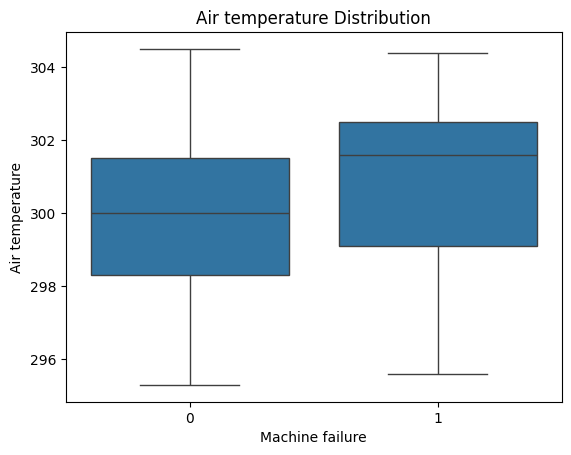

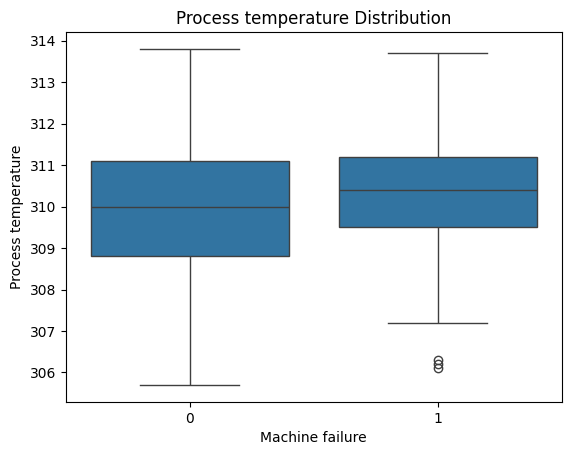

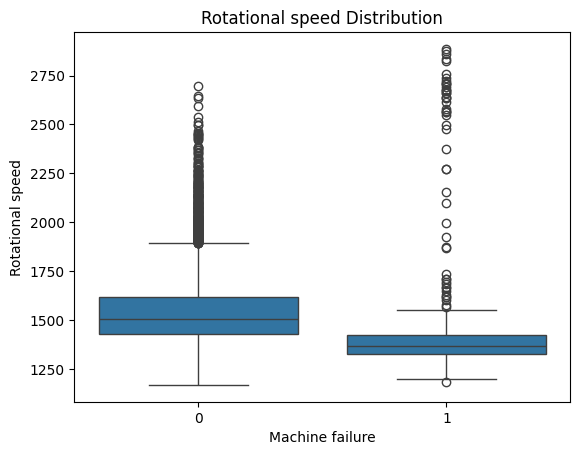

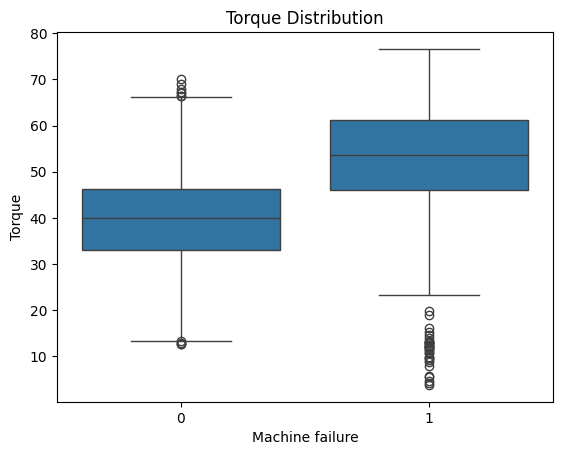

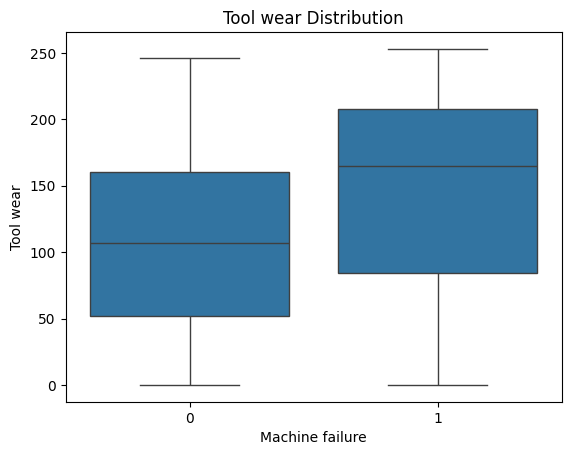

In [56]:
col =['Air temperature', 'Process temperature', 'Rotational speed','Torque', 'Tool wear']
# for c in col:
#   fig = px.box(df, x='Machine failure', y=c)
#   fig.show()
for c in col:
  sns.boxplot(data = df, x= 'Machine failure', y=c)
  plt.title(f'{c} Distribution')
  plt.show()



**Encode (Type)**

In [57]:
df = pd.get_dummies(df, columns=['Type'], drop_first=True)

**Feature Engineering:**

1. Temperature_Difference

In [58]:
df['Temperature_Difference'] = df['Process temperature'] - df['Air temperature']

2. Power

In [59]:
df['Power'] = df['Torque'] * df['Rotational speed']

**Showing Correlation:**

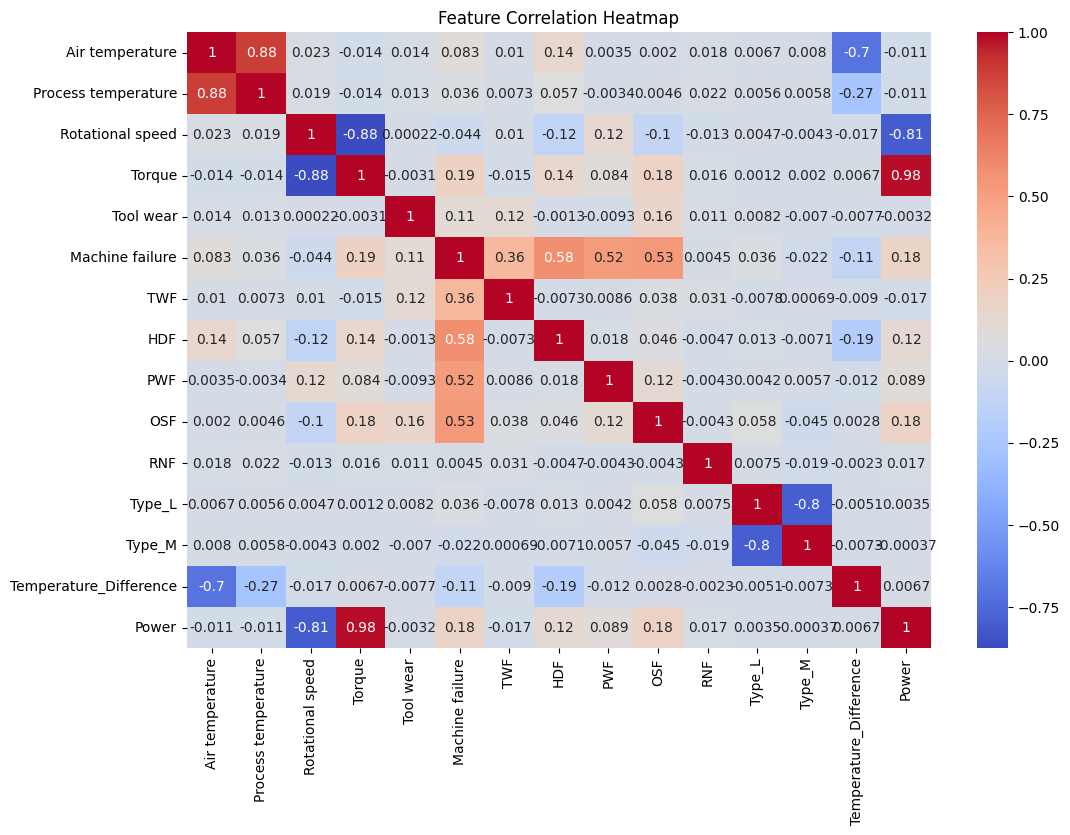

In [60]:
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(numeric_only=True), annot=True,cmap='coolwarm')
plt.title('Feature Correlation Heatmap')
plt.show()

In [62]:
print("Saving the Prepare processed data...",df.to_csv('data/predictive_maintenance_2.csv', index=False))

Saving the Prepare processed data... None


In [87]:
%cd /content/drive/MyDrive/Machine_Failure_Project

/content/drive/MyDrive/Machine_Failure_Project


In [88]:
!git status

On branch main
Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   notebooks/01_eda_data_preprocessing.ipynb

no changes added to commit (use "git add" and/or "git commit -a")


In [89]:
!git remote set-url origin https://github.com/opyadav-07/machine-failure-prediction-using-machine-learning.git

In [90]:
!git remote -v

origin	https://github.com/opyadav-07/machine-failure-prediction-using-machine-learning.git (fetch)
origin	https://github.com/opyadav-07/machine-failure-prediction-using-machine-learning.git (push)


In [91]:
!git branch -M main